# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [16]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* I chose line chart because it shows how each continent’s population changed over time relative to its own 1970 population. Blue highlights Africa, which grew the fastest, while grey keeps the other continents visible for comparison.

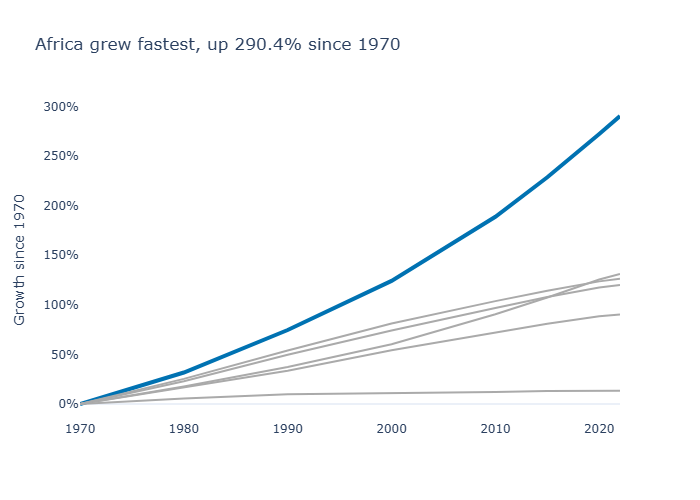

In [17]:
growth = df_long.groupby(["Year", "Continent"])["Population"].sum().unstack()
growth = growth.div(growth.loc[1970]).sub(1)

fig = px.line(
    growth,
    template="plotly_white",
    title=f"Africa grew fastest, up {growth.loc[2022, 'Africa']:.1%} since 1970",
    labels={"value": "Growth since 1970", "variable": "Continent"},
)

fig.update_traces(line_color="#AAAAAA", line_width=2)
fig.update_traces(line_color="#0072B2", line_width=4, selector=dict(name="Africa"))
fig.update_layout(showlegend=False)
fig.update_xaxes(showgrid=False, title_text="")
fig.update_yaxes(showgrid=False, tickformat=".0%")
fig.show(renderer="png")

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* I chose a sorted horizontal bar chart because it makes the countries easy to rank and their population gains easy to compare. Blue highlights the four African countries in the top 15, while grey shows the rest. The four african countries are nigeria,ethiopia,DR Congo, and Egypt.

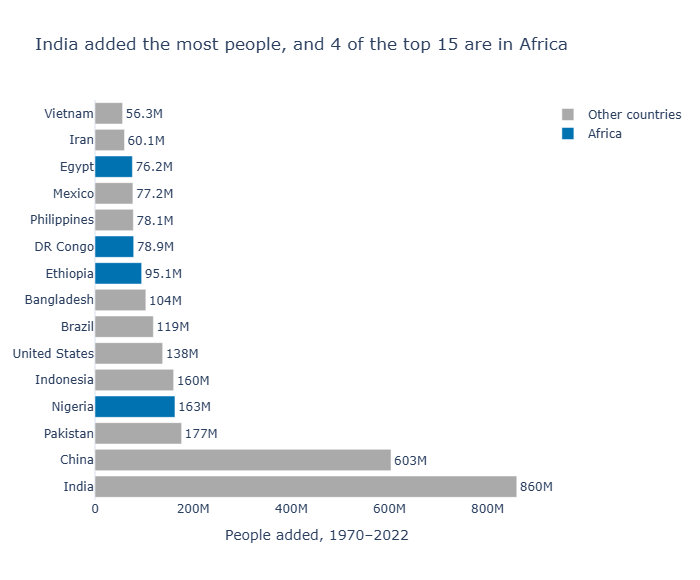

In [18]:
# Q2
top = df.assign(Added=df["2022 Population"] - df["1970 Population"])
top = top.nlargest(15, "Added").sort_values("Added")
top["Group"] = top["Continent"].where(top["Continent"].eq("Africa"), "Other countries")
africa_count = top["Group"].eq("Africa").sum()

fig = px.bar(
    top, x="Added", y="Country", color="Group", orientation="h",
    category_orders={"Country": top["Country"].tolist()},
    color_discrete_map={"Africa": "#0072B2", "Other countries": "#AAAAAA"},
    text="Added", template="plotly_white", height=580,
    title=f"India added the most people, and {africa_count} of the top 15 are in Africa",
    labels={"Added": "People added, 1970–2022", "Group": ""},
)

fig.update_traces(texttemplate="%{x:.3s}", textposition="outside", cliponaxis=False)
fig.update_xaxes(showgrid=False, tickformat="~s")
fig.update_yaxes(title_text=None)
fig.show(renderer="png")

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* I chose a scatter plot because it shows how land area and population relate, with marker shapes distinguishing continents. Log scales keep small and large countries readable, and labels flag examples that stand out, such as densely populated Bangladesh and sparsely populated Greenland.

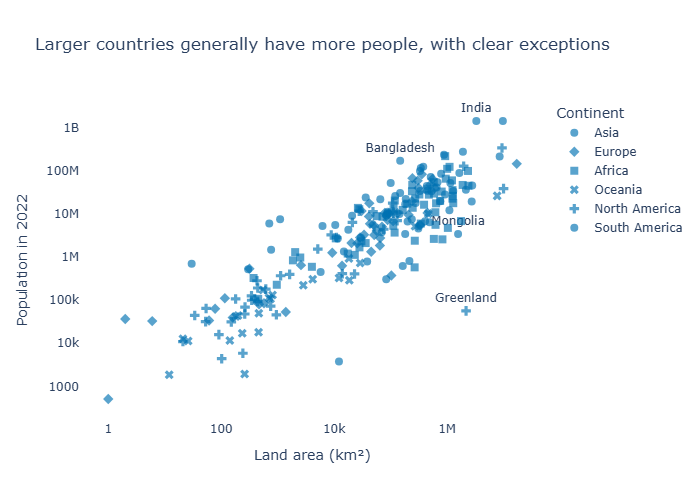

In [19]:
# Q3
outliers = ["Bangladesh", "India", "Greenland", "Mongolia"]
plot = df.assign(Label=df["Country"].where(df["Country"].isin(outliers), ""))

fig = px.scatter(
    plot, x="Area", y="2022 Population", symbol="Continent",
    text="Label", hover_name="Country", log_x=True, log_y=True,
    color_discrete_sequence=["#0072B2"], template="plotly_white",
    title="Larger countries generally have more people, with clear exceptions",
    labels={"Area": "Land area (km²)", "2022 Population": "Population in 2022"},
)

fig.update_traces(marker=dict(size=8, opacity=0.65), textposition="top center")
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)
fig.show(renderer="png")

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* I chose a box plot because it compares median density, spread, and outliers across continents. The log scale keeps very sparse and very dense places visible on the same chart.

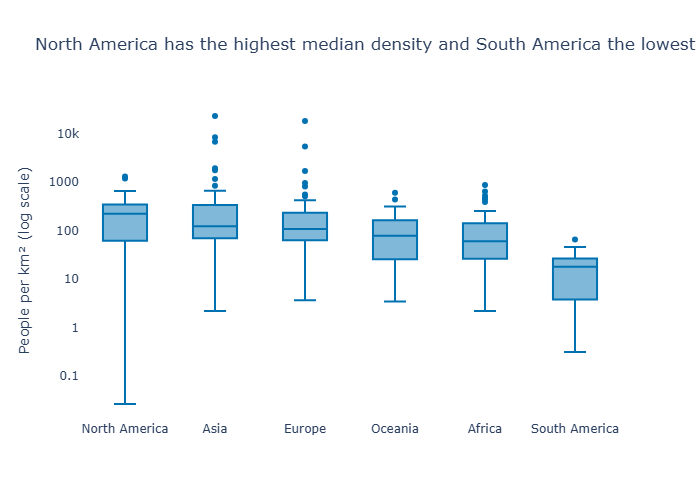

In [20]:
# Q4
order = df.groupby("Continent")["Density"].median().sort_values(ascending=False)

fig = px.box(
    df, x="Continent", y="Density", points="outliers",
    hover_name="Country", log_y=True, template="plotly_white",
    category_orders={"Continent": order.index.tolist()},
    color_discrete_sequence=["#0072B2"],
    title="North America has the highest median density and South America the lowest",
    labels={"Density": "People per km² (log scale)"},
)

fig.update_xaxes(title_text=None)
fig.update_yaxes(showgrid=False)
fig.show(renderer="png")

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* I chose a choropleth map because it shows where population growth and decline occurred. Blue indicates growth, orange indicates decline, and a neutral midpoint marks zero change.

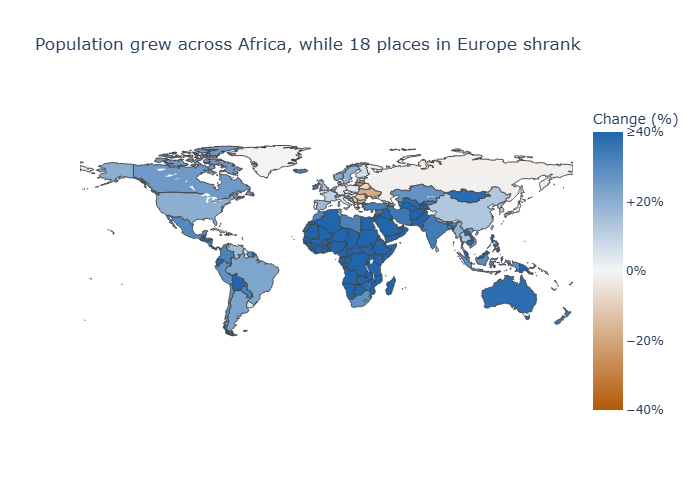

In [21]:
change = df["2022 Population"].div(df["2000 Population"]).sub(1).mul(100)
world = df.assign(Change=change)

fig = px.choropleth(
    world, locations="CCA3", locationmode="ISO-3", color="Change",
    hover_name="Country", hover_data={"CCA3": False, "Change": "+.1f"},
    color_continuous_scale=["#B35806", "#F5F5F5", "#2166AC"],
    range_color=(-40, 40), template="plotly_white",
    title="Population grew across Africa, while 18 places in Europe shrank",
    labels={"Change": "Change (%)"},
)

fig.update_coloraxes(
    colorbar=dict(tickvals=[-40, -20, 0, 20, 40],
                  ticktext=["−40%", "−20%", "0%", "+20%", "≥40%"])
)
fig.update_geos(showframe=False, showcoastlines=False)
fig.show(renderer="png")

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* I chose a treemap because it shows countries nested inside their continents, with each rectangle sized by its 2022 population. Blue highlights Asia, which accounts for 59.2% of the world population in the dataset.

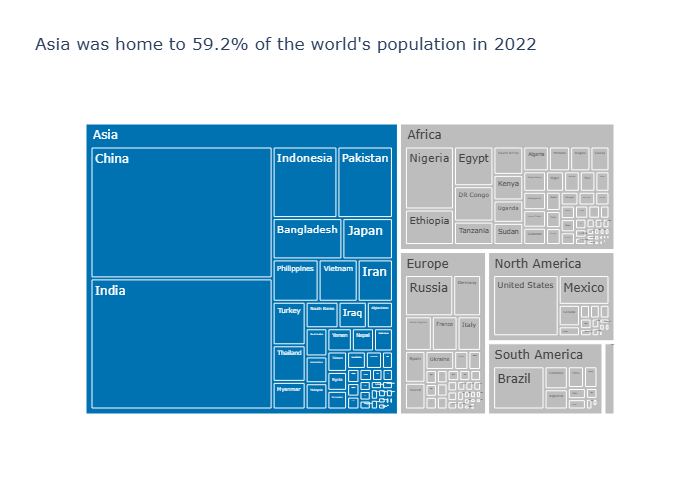

In [22]:
# Q6
# YOUR CODE HERE
population = "2022 Population"
asia_share = df.loc[df["Continent"].eq("Asia"), population].sum() / df[population].sum()

fig = px.treemap(
    df, path=["Continent", "Country"], values=population, color="Continent",
    color_discrete_map={"Asia": "#0072B2"},
    color_discrete_sequence=["#BDBDBD"],
    template="plotly_white",
    title=f"Asia was home to {asia_share:.1%} of the world's population in 2022",
)

fig.update_traces(hovertemplate="<b>%{label}</b><br>%{value:,} people<extra></extra>")
fig.show(renderer="png")

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* I chose a 100% stacked bar chart because each bar represents the entire world population for that year, making the four shares easy to compare over time. Blue highlights Africa, whose share rose the most.

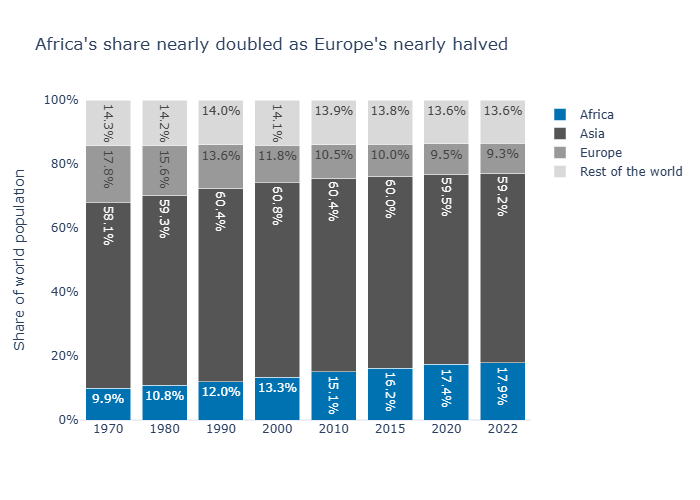

In [23]:
# Q7
groups = ["Africa", "Asia", "Europe", "Rest of the world"]
region = df_long["Continent"].where(
    df_long["Continent"].isin(groups), "Rest of the world"
)

shares = (
    df_long.assign(Region=region)
    .groupby(["Year", "Region"], as_index=False)["Population"].sum()
)
shares["Share"] = shares["Population"] / shares.groupby("Year")["Population"].transform("sum")
shares["Year"] = shares["Year"].astype(str)

fig = px.bar(
    shares, x="Year", y="Share", color="Region", text="Share",
    barmode="stack", template="plotly_white",
    category_orders={"Region": groups, "Year": sorted(shares["Year"].unique())},
    color_discrete_sequence=["#0072B2", "#555555", "#999999", "#D9D9D9"],
    title="Africa's share nearly doubled as Europe's nearly halved",
    labels={"Share": "Share of world population"},
)

fig.update_traces(texttemplate="%{y:.1%}", textposition="inside")
fig.update_layout(legend_title_text="")
fig.update_xaxes(title_text=None)
fig.update_yaxes(tickformat=".0%", range=[0, 1], showgrid=False)
fig.show(renderer="png")